**Técnicas de Aprendizaje Automático**

_Máster Universitario en Inteligencia Artificial_

# Actividad: Clasificación con máquinas de vectores de soporte y árboles de decisión

## Objetivos

Mediante esta actividad se pretende que ponga en práctica la creación de modelos basados en máquinas de vectores de soporte y árboles de decisión. El objetivo es comprender de forma práctica con un problema determinado las diferencias que existen a la hora de entrenar los diferentes modelos.

- Comprender el tratamiento de datos que hay que realizar para los modelos de clasificación.
- Entender y aplicar el algoritmo **Árboles de decisión** a un problema de clasificación.
- Entender y aplicar el algoritmo **Support Vector Machine** a un problema de clasificación.
- Evaluar y analizar los resultados de los clasificadores.
- Investigar la aplicación de los modelos de clasificación a problemas reales.


## Descripción de la actividad

Debes completar los espacios indicados en el notebook con el código solicitado y la respuesta, en función de lo que se solicite. Ten en cuenta que las celdas vacías indican cuántas líneas debe ocupar la respuesta, por lo general no más de una línea.

El conjunto de datos con el que vamos a trabajar se encuentra en el siguiente enlace: https://archive.ics.uci.edu/dataset/31/covertype

Este dataset ha sido generado para predecir el tipo de cubierta forestal únicamente a partir de variables cartográficas (sin datos de sensores remotos). El tipo de cubierta forestal real para una observación determinada (celda de 30 x 30 metros) se determinó a partir de los datos del Sistema de información de recursos (RIS) de la Región 2 del Servicio Forestal de EE. UU. (USFS). Las variables independientes se derivaron de datos obtenidos originalmente del Servicio Geológico de EE. UU. (USGS) y de datos del USFS. Los datos están en forma original (no escalados) y contienen columnas binarias (0 o 1) de datos para variables cualitativas independientes (áreas silvestres y tipos de suelo).
Para ampliar información sobre el dataset y su origen, recomendamos leer la descripción completa del dataset en el enlace del repositorio. l.

El objetivo de la clasificación será detectar el tipo de cubierta forestal.

### Tareas que se deben realizar

- Análisis descriptivo de los datos:
   - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Clasificación:
  - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Investigación:
  - Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de clasificación empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.
  - Para el artículo indicar:
    - Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la **clasificación**.
    - Cómo utilizan las técnicas de **clasificación**, si realizan alguna adaptación de los algoritmos, esta deberá indicarse.
    - Principales resultados de la aplicación y de la investigación.


### Nota sobre el uso de Inteligencia Artificial (IA generativa)

En esta actividad utilicé un asistente de IA (Claude, de Anthropic) en dos fases.

En la primera versión del cuaderno me apoyé en él para organizar la explicación de los hiperparámetros de `DecisionTreeClassifier` y `SVC` a partir de la documentación oficial de scikit-learn, para escribir y depurar el código de entrenamiento, las matrices de confusión y las métricas por clase, y para buscar artículos candidatos para la sección de investigación.

En una segunda fase le pedí una revisión crítica del cuaderno frente a la rúbrica. Esa revisión detectó tres problemas: la carga con `fetch_ucirepo(id=31)` desplazaba los nombres de las variables binarias, porque el paquete entrega las columnas en un orden distinto al del fichero original; varios textos citaban cifras de una ejecución anterior; y la explicación de `decision_function_shape` era incorrecta. A partir de esa revisión, el asistente reescribió la carga de datos y añadió cuatro elementos: la razón de correlación η, la comprobación empírica de que el árbol no depende del escalado, la validación cruzada para elegir `C` y la comparación del árbol y el SVM en igualdad de condiciones. También redactó de nuevo las respuestas con las cifras de la ejecución final y propuso sustituir el artículo inicial, basado en XGBoost, por uno que aplica SVM directamente.

Revisé esos cambios y soy responsable del contenido entregado. El cuaderno se ejecutó completo y en orden desde un kernel limpio, y cada cifra citada en el texto procede de las salidas de esa ejecución.

[Gabriel Morejón López](https://www.linkedin.com/in/gabriel-eduardo-morejon-lopez/)

[Repositorio en GitHub](https://github.com/elgabo82/CoverType_TAA-UNIR-A2.git)

[ORCID](https://orcid.org/0000-0001-8902-4583)

**Referencia de la IA (APA, 7.ª ed.)**
Anthropic. (2026). Claude (Version 5 Sonnet), (Versión 5.5 Opus, Esfuerzo alto) [Sonnet, Opus]. https://claude.ai/share/7ebf166f-e39a-497a-9bc2-74ece0270fea

### Análisis descriptivo de los datos

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = (7, 5)

NOMBRES_CLASE = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine', 4: 'Cottonwood/Willow',
                 5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}

In [2]:
# Instala ucimlrepo solo si no está disponible (se usa cuando no existe la copia local de los datos)
import importlib.util
if importlib.util.find_spec('ucimlrepo') is None:
    %pip install -q ucimlrepo
else:
    print("ucimlrepo ya está instalado.")

ucimlrepo ya está instalado.


In [3]:
# Se carga el dataset.
# La descarga oficial de UCI (https://archive.ics.uci.edu/dataset/31/covertype) trae covtype.data.gz y
# covtype.info, sin fila de cabecera. Si el fichero está en la carpeta local covertype/, se lee directamente
# con los nombres de columna documentados en covtype.info; si no, se descarga con ucimlrepo.
#
# Cuidado: fetch_ucirepo(id=31) NO devuelve las columnas en el orden del fichero original. Sus metadatos
# listan Wilderness_Area1, luego Soil_Type1..Soil_Type40 y al final Wilderness_Area2..Wilderness_Area4.
# Por eso las columnas se seleccionan POR NOMBRE: renombrarlas por posición desplaza las etiquetas de
# 43 de las 44 variables binarias.

columnas = (
    ["Elevation", "Aspect", "Slope",
     "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
     "Horizontal_Distance_To_Roadways",
     "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
     "Horizontal_Distance_To_Fire_Points"]
    + [f"Wilderness_Area{i}" for i in range(1, 5)]
    + [f"Soil_Type{i}" for i in range(1, 41)]
    + ["Cover_Type"]
)

ruta_local = Path('covertype/covtype.data.gz')
if ruta_local.exists():
    df = pd.read_csv(ruta_local, header=None, names=columnas, compression='gzip')
    print(f"Datos cargados desde {ruta_local} (fichero original de UCI).")
else:
    from ucimlrepo import fetch_ucirepo
    covertype = fetch_ucirepo(id=31)
    df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)[columnas]
    print("Datos cargados con ucimlrepo; columnas reordenadas por nombre.")

print(df.shape)
df.head()

Datos cargados desde covertype/covtype.data.gz (fichero original de UCI).
(581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


¿Cuántas instancias de datos tiene el dataset?

In [4]:
print(f"El dataset tiene {df.shape[0]} instancias (filas) y {df.shape[1]} columnas "
      f"(incluyendo la variable de clase Cover_Type).")


El dataset tiene 581012 instancias (filas) y 55 columnas (incluyendo la variable de clase Cover_Type).


El dataset tiene **581.012 instancias**. Cada una corresponde a una celda de 30 × 30 m de cuatro áreas silvestres del Bosque Nacional Roosevelt (Colorado) y se describe con 54 variables predictoras más la clase `Cover_Type`, 55 columnas en total.

¿Cuántas variables continuas hay en el dataset?

In [5]:
variables_continuas = ["Elevation", "Aspect", "Slope",
                       "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
                       "Horizontal_Distance_To_Roadways",
                       "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
                       "Horizontal_Distance_To_Fire_Points"]

print(f"Hay {len(variables_continuas)} variables continuas:")
for v in variables_continuas:
    print(" -", v)


Hay 10 variables continuas:
 - Elevation
 - Aspect
 - Slope
 - Horizontal_Distance_To_Hydrology
 - Vertical_Distance_To_Hydrology
 - Horizontal_Distance_To_Roadways
 - Hillshade_9am
 - Hillshade_Noon
 - Hillshade_3pm
 - Horizontal_Distance_To_Fire_Points


Hay **10** variables continuas: `Elevation`, `Aspect`, `Slope`, `Horizontal_Distance_To_Hydrology`, `Vertical_Distance_To_Hydrology`, `Horizontal_Distance_To_Roadways`, `Hillshade_9am`, `Hillshade_Noon`, `Hillshade_3pm` y `Horizontal_Distance_To_Fire_Points`. Se miden en metros, grados o un índice de sombreado de 0 a 255, y se almacenan como enteros sin escalar. `Aspect` es además una variable circular: 0° y 360° representan la misma orientación, algo que ninguno de los dos modelos tiene en cuenta de forma explícita. El resto de columnas son binarias (0/1) y codifican variables categóricas.

¿Cuántas variables categóricas hay en el dataset? Indica las categorías.

Hay **2 variables categóricas** en su forma original, codificadas mediante *one-hot encoding* en 44 columnas binarias:

- **`Wilderness_Area`**, con 4 categorías: 1) Rawah, 2) Neota, 3) Comanche Peak y 4) Cache la Poudre.
- **`Soil_Type`**, con 40 categorías, que corresponden a las unidades ecológicas de terreno (ELU) del Servicio Forestal descritas en `covtype.info`.

La celda siguiente comprueba que cada fila tiene exactamente un `1` en cada grupo. También muestra que las categorías están muy desigualmente representadas: Rawah y Comanche Peak reúnen el 88,5 % de las observaciones, y hay suelos casi vacíos (`Soil_Type15` aparece solo 3 veces y `Soil_Type7`, 105). La propia `Cover_Type` también es categórica, con 7 clases nominales, pero es la etiqueta a predecir, no una variable predictora.

In [6]:
# Verificación: cada fila debe tener exactamente un 1 entre las columnas de cada variable categórica
wa_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
st_cols = [c for c in df.columns if c.startswith('Soil_Type')]

suma_wa = df[wa_cols].sum(axis=1)
suma_st = df[st_cols].sum(axis=1)
print("Valores únicos de la suma por fila en Wilderness_Area:", suma_wa.unique())
print("Valores únicos de la suma por fila en Soil_Type:      ", suma_st.unique())
assert (suma_wa == 1).all() and (suma_st == 1).all(), "Codificación one-hot inconsistente: revisar el orden de columnas"

nombres_area = {'Wilderness_Area1': 'Rawah', 'Wilderness_Area2': 'Neota',
                'Wilderness_Area3': 'Comanche Peak', 'Wilderness_Area4': 'Cache la Poudre'}
print("\nObservaciones por área silvestre:")
print(df[wa_cols].sum().rename(nombres_area).to_string())

frecuencia_suelo = df[st_cols].sum().sort_values()
print("\nTipos de suelo menos frecuentes:")
print(frecuencia_suelo.head(5).to_string())

Valores únicos de la suma por fila en Wilderness_Area: [1]
Valores únicos de la suma por fila en Soil_Type:       [1]

Observaciones por área silvestre:
Rawah              260796
Neota               29884
Comanche Peak      253364
Cache la Poudre     36968

Tipos de suelo menos frecuentes:
Soil_Type15      3
Soil_Type7     105
Soil_Type36    119
Soil_Type8     179
Soil_Type37    298


¿Cómo es la distribución de etiquetas de clase en el dataset? Con estos datos, ¿podríamos decir que el dataset está balanceado?

             especie  instancias  porcentaje (%)
1         Spruce/Fir      211840           36.46
2     Lodgepole Pine      283301           48.76
3     Ponderosa Pine       35754            6.15
4  Cottonwood/Willow        2747            0.47
5              Aspen        9493            1.63
6        Douglas-fir       17367            2.99
7          Krummholz       20510            3.53

Razón clase mayoritaria / minoritaria: 103.1 a 1


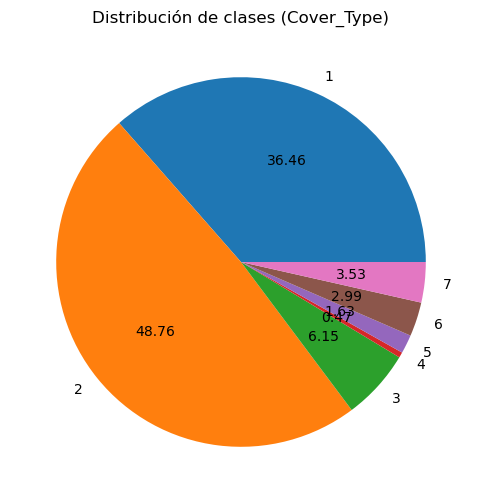

In [7]:
conteo = df['Cover_Type'].value_counts().sort_index()
porcentaje = df['Cover_Type'].value_counts(normalize=True).sort_index() * 100
resumen = pd.DataFrame({'especie': pd.Series(NOMBRES_CLASE), 'instancias': conteo,
                        'porcentaje (%)': porcentaje.round(2)})
print(resumen)
print(f"\nRazón clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.1f} a 1")

fig, ax = plt.subplots(figsize=(6, 6))
conteo.plot(kind='pie', autopct='%.2f', ax=ax)
ax.set_ylabel('')
ax.set_title('Distribución de clases (Cover_Type)')
plt.show()

La distribución está **muy desbalanceada**. Las clases 1 (Spruce/Fir, 36,46 %) y 2 (Lodgepole Pine, 48,76 %) concentran juntas el 85,2 % de las instancias, mientras que la clase 4 (Cottonwood/Willow) apenas llega al 0,47 % (2.747 ejemplos) y la clase 5 (Aspen) al 1,63 %.

No, **no podemos decir que el dataset esté balanceado**: la clase mayoritaria tiene 103 veces más ejemplos que la minoritaria. Esto importa por dos motivos. Un modelo que siempre prediga la clase 2 ya acertaría casi la mitad de las veces, así que la accuracy global puede engañar. Además, las clases minoritarias ofrecen muchos menos ejemplos de los que aprender. Ambas cosas se reflejan más adelante: en el árbol de decisión entrenado con el dataset completo, las clases 4 y 5 son las de menor recall.

¿Existen valores nulos o perdidos en el dataset?

In [8]:
nulos = df.isnull().sum()
print("Total de valores nulos en todo el dataset:", nulos.sum())
if nulos.sum() > 0:
    print(nulos[nulos > 0])
else:
    print("Ninguna de las 55 columnas tiene valores nulos.")


Total de valores nulos en todo el dataset: 0
Ninguna de las 55 columnas tiene valores nulos.


**No existen valores nulos ni perdidos** en ninguna de las 55 columnas. Es coherente con `covtype.info` («Missing Attribute Values: None»): las variables se derivaron de forma automática de datos cartográficos del USGS y del USFS para cada celda, sin depender de mediciones manuales que pudieran quedar incompletas.

¿Existe alguna variable altamente correlacionada con la variable de clase?

_Nota: Para responder a esto, como es muy difícil ver la matriz de correlaciones, recomendamos filtrar aquellas correlaciones superiores al 0.80 con la variable de clase.

In [9]:
correlaciones = df.corr(numeric_only=True)['Cover_Type'].drop('Cover_Type')
correlaciones_altas = correlaciones[correlaciones.abs() > 0.80]

print("Variables con |correlación de Pearson| > 0.80 respecto a Cover_Type:")
print(correlaciones_altas if not correlaciones_altas.empty else "Ninguna variable supera el umbral de 0.80.")

print("\nTop 10 correlaciones con Cover_Type (por valor absoluto):")
print(correlaciones.reindex(correlaciones.abs().sort_values(ascending=False).index).head(10))

Variables con |correlación de Pearson| > 0.80 respecto a Cover_Type:
Ninguna variable supera el umbral de 0.80.

Top 10 correlaciones con Cover_Type (por valor absoluto):
Wilderness_Area4                   0.323200
Elevation                         -0.269554
Soil_Type10                        0.243876
Wilderness_Area1                  -0.203913
Soil_Type38                        0.160170
Soil_Type39                        0.155668
Horizontal_Distance_To_Roadways   -0.153450
Slope                              0.148285
Soil_Type22                       -0.141746
Soil_Type23                       -0.135055
Name: Cover_Type, dtype: float64


In [10]:
# Pearson trata Cover_Type como si 1..7 fueran magnitudes ordenadas, pero son etiquetas nominales:
# si se renumeraran las especies, el coeficiente cambiaría. La razón de correlación η (eta) no depende de
# esa codificación: mide qué fracción de la variabilidad de cada variable se explica por la clase.
def razon_correlacion(x, y):
    media = x.mean()
    grupos = x.groupby(y)
    ss_entre = (grupos.count() * (grupos.mean() - media) ** 2).sum()
    ss_total = ((x - media) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)

eta = pd.Series({c: razon_correlacion(df[c], df['Cover_Type'])
                 for c in df.columns.drop('Cover_Type')}).sort_values(ascending=False)
print("Variables con η > 0.80:", list(eta[eta > 0.80].index) or "ninguna")
print("\nTop 10 según la razón de correlación η:")
print(eta.head(10).round(3))

Variables con η > 0.80: ninguna

Top 10 según la razón de correlación η:
Elevation                          0.785
Wilderness_Area4                   0.736
Soil_Type10                        0.471
Soil_Type4                         0.342
Soil_Type38                        0.341
Soil_Type39                        0.331
Soil_Type3                         0.326
Wilderness_Area1                   0.311
Horizontal_Distance_To_Roadways    0.310
Soil_Type2                         0.310
dtype: float64


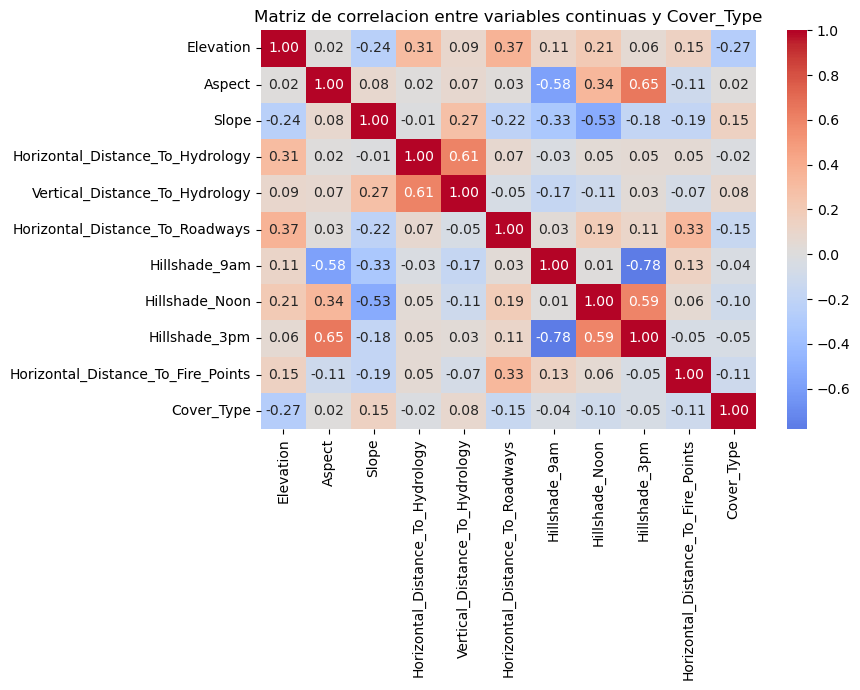

In [11]:
quant_cols = variables_continuas + ['Cover_Type']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[quant_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Matriz de correlacion entre variables continuas y Cover_Type')
plt.tight_layout()
plt.show()


In [12]:
# Hay pares de variables PREDICTORAS (no la clase) muy correlacionadas entre si?
# Es relevante para valorar multicolinealidad antes de modelar.
corr_matrix = df.drop(columns=['Cover_Type']).corr()
cols = corr_matrix.columns
pares_altos = [
    (cols[i], cols[j], round(corr_matrix.iloc[i, j], 3))
    for i in range(len(cols)) for j in range(i + 1, len(cols))
    if abs(corr_matrix.iloc[i, j]) > 0.80
]
print(f"Pares de variables predictoras con |correlacion| > 0.80: {len(pares_altos)}")
for p in pares_altos:
    print(p)


Pares de variables predictoras con |correlacion| > 0.80: 0


No. **Ninguna variable supera |r| = 0,80** con `Cover_Type`. La correlación de Pearson más alta es la de `Wilderness_Area4` (Cache la Poudre, r = 0,323), seguida de `Elevation` (−0,270) y `Soil_Type10` (0,244).

Pearson es, además, una medida discutible en este caso. Trata los códigos 1 a 7 como magnitudes ordenadas, cuando en realidad son especies, así que renumerarlas cambiaría el coeficiente. La razón de correlación η no depende de esa numeración y da una imagen más fiel. `Elevation` (η = 0,785) y `Wilderness_Area4` (0,736) se acercan al umbral sin superarlo. A partir de la tercera variable, `Soil_Type10` (0,471), la relación cae con rapidez.

Hay; por tanto, dos variables con una relación fuerte con la clase, pero ninguna altamente correlacionada en sentido estricto. El tipo de cubierta depende de combinaciones de variables. Ese es el tipo de frontera no lineal que pueden aprender un árbol de decisión o un SVM con kernel RBF, y no un modelo lineal simple.

¿Cómo son las correlaciones entre las variables del dataset?

Entre las variables predictoras no hay ningún par con |r| > 0,80 (celda anterior), así que no existe multicolinealidad severa que obligue a eliminar variables. Sí hay correlaciones moderadas en la matriz de las variables continuas, y todas tienen una explicación física clara. El índice de sombreado se calcula a partir de la orientación y la pendiente del terreno respecto a la posición del sol:

- `Hillshade_9am` y `Hillshade_3pm` (r = −0,78): una ladera orientada al este recibe sol por la mañana y sombra por la tarde, y a la inversa.
- `Aspect` con `Hillshade_3pm` (0,65) y con `Hillshade_9am` (−0,58): las orientaciones al oeste, de azimut alto, se iluminan por la tarde.
- `Hillshade_Noon` con `Hillshade_3pm` (0,59) y con `Slope` (−0,53): cuanto más empinada es la ladera, menos luz directa recibe al mediodía.
- `Horizontal_Distance_To_Hydrology` con `Vertical_Distance_To_Hydrology` (0,61): cuanto más lejos está el agua en horizontal, mayor suele ser el desnivel hasta ella.
- `Elevation` con `Horizontal_Distance_To_Roadways` (0,37) y con `Horizontal_Distance_To_Hydrology` (0,31): las zonas altas quedan más alejadas de carreteras y cauces.

El resto de pares está por debajo de 0,35 en valor absoluto. Las columnas binarias de un mismo grupo son mutuamente excluyentes, así que entre ellas solo aparecen correlaciones negativas débiles, por construcción.

¿Qué tres variables del dataset consideras que pueden influenciar más en la clasificación de los datos?¿Qué pruebas harías para comprobar tus hipótesis? **Realiza dichas pruebas**.

Top 5 variables según ANOVA F-test:
Elevation           155306.9
Wilderness_Area4    114625.9
Soil_Type10          27680.0
Soil_Type4           12798.3
Soil_Type38          12729.5
dtype: float64

Top 5 variables según importancia en Random Forest (muestra estratificada de 50.000):
Elevation                             0.3596
Wilderness_Area4                      0.0694
Horizontal_Distance_To_Roadways       0.0663
Horizontal_Distance_To_Fire_Points    0.0557
Horizontal_Distance_To_Hydrology      0.0317
dtype: float64

Variables candidatas en las tres medidas:
                                 F (ANOVA)  posición F  importancia RF  \
Elevation                         155307.0           1           0.360   
Wilderness_Area4                  114626.0           2           0.069   
Horizontal_Distance_To_Roadways    10276.0           9           0.066   

                                 posición RF      η  
Elevation                                  1  0.785  
Wilderness_Area4             

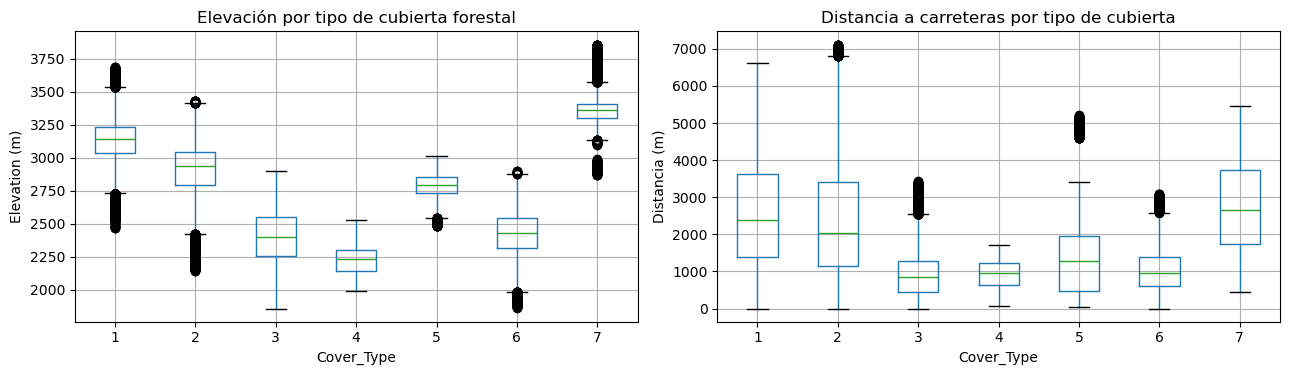

In [13]:
# Prueba de hipótesis: ¿qué variables influyen más en la clasificación?
# (1) ANOVA F-test (f_classif) entre cada variable y Cover_Type: mide diferencias de medias entre clases,
#     variable por variable.
# (2) Importancia de variables de un Random Forest de referencia entrenado sobre una muestra estratificada
#     de 50.000 filas: capta además interacciones entre variables.
# Si ambas pruebas coinciden, la evidencia es más sólida que con una sola.

from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split as tts_hyp

X_all = df.drop(columns=['Cover_Type'])
y_all = df['Cover_Type']

f_vals, p_vals = f_classif(X_all, y_all)
f_series = pd.Series(f_vals, index=X_all.columns).sort_values(ascending=False)
print("Top 5 variables según ANOVA F-test:")
print(f_series.head(5).round(1))

X_muestra, _, y_muestra, _ = tts_hyp(X_all, y_all, train_size=50000, stratify=y_all, random_state=1)
rf_ref = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=1, n_jobs=-1)
rf_ref.fit(X_muestra, y_muestra)
importancias = pd.Series(rf_ref.feature_importances_, index=X_all.columns).sort_values(ascending=False)
print("\nTop 5 variables según importancia en Random Forest (muestra estratificada de 50.000):")
print(importancias.head(5).round(4))

candidatas = ['Elevation', 'Wilderness_Area4', 'Horizontal_Distance_To_Roadways']
tabla_candidatas = pd.DataFrame({
    'F (ANOVA)': f_series[candidatas].round(0),
    'posición F': f_series.rank(ascending=False).astype(int)[candidatas],
    'importancia RF': importancias[candidatas].round(3),
    'posición RF': importancias.rank(ascending=False).astype(int)[candidatas],
    'η': eta[candidatas].round(3),
})
print("\nVariables candidatas en las tres medidas:")
print(tabla_candidatas)

print("\nElevation, media y desviación estándar por clase:")
print(df.groupby('Cover_Type')['Elevation'].agg(['mean', 'std']).round(1))
print("\nPorcentaje de cada clase dentro de Cache la Poudre (Wilderness_Area4 = 1):")
print((df.loc[df['Wilderness_Area4'] == 1, 'Cover_Type'].value_counts(normalize=True).sort_index() * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.boxplot(column='Elevation', by='Cover_Type', ax=axes[0])
axes[0].set_title('Elevación por tipo de cubierta forestal')
axes[0].set_xlabel('Cover_Type'); axes[0].set_ylabel('Elevation (m)')
df.boxplot(column='Horizontal_Distance_To_Roadways', by='Cover_Type', ax=axes[1])
axes[1].set_title('Distancia a carreteras por tipo de cubierta')
axes[1].set_xlabel('Cover_Type'); axes[1].set_ylabel('Distancia (m)')
plt.suptitle('')
plt.tight_layout()
plt.show()

Las tres variables que considero más influyentes son **`Elevation`**, **`Wilderness_Area4`** (Cache la Poudre) y **`Horizontal_Distance_To_Roadways`**.

Para comprobarlo apliqué dos pruebas independientes sobre las 54 variables: un ANOVA F-test y la importancia de variables de un Random Forest entrenado con una muestra estratificada de 50.000 filas. A ellas sumé la razón η calculada antes. Las dos primeras posiciones coinciden en ambas pruebas; la tercera no, y esa diferencia es informativa.

- **`Elevation`** domina todas las medidas (F ≈ 155.307; importancia RF = 0,360; η = 0,785). Las medias por clase van de 2.224 m (Cottonwood/Willow) a 3.362 m (Krummholz), y el boxplot muestra rangos casi disjuntos entre varias clases, como anticipa la documentación del dataset.
- **`Wilderness_Area4`** ocupa el segundo puesto en las dos pruebas (F ≈ 114.626; importancia = 0,069; η = 0,736). Cache la Poudre es el área de menor elevación y su composición es muy distinta del resto: el 58,0 % de sus celdas son Ponderosa Pine, el 26,3 % Douglas-fir y el 7,4 % Cottonwood/Willow, especie que prácticamente solo aparece allí.
- **`Horizontal_Distance_To_Roadways`** es tercera en el Random Forest (0,066, casi empatada con `Wilderness_Area4`), pero solo novena en el ANOVA (F ≈ 10.276). El ANOVA mide diferencias de medias variable por variable; el bosque capta su utilidad en combinación con la elevación y el área, porque funciona como indicador de la ubicación dentro de cada área silvestre. En el ANOVA, el tercer puesto lo ocupa `Soil_Type10` (F ≈ 27.680), que el bosque no sitúa en su top 5.

Elegí `Horizontal_Distance_To_Roadways` en lugar de `Soil_Type10` porque la prueba multivariante refleja mejor lo que harán los modelos, que combinan variables. La conclusión encaja con la pregunta anterior: ninguna variable por sí sola explica la clase, pero la elevación, el área y la posición juntas separan razonablemente bien las 7 especies.

### Clasificación

In [14]:
# Separamos los datos en los conjuntos de entrenamiento y test.
# stratify=y conserva en ambos conjuntos la proporción de cada clase, importante con clases tan minoritarias.
from sklearn.model_selection import train_test_split

X, y = df.drop('Cover_Type', axis=1), df['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
print(f"Entrenamiento: {len(X_train)} ejemplos · Test: {len(X_test)} ejemplos")

Entrenamiento: 464809 ejemplos · Test: 116203 ejemplos


**Árboles de decisión**

En esta parte de la actividad, hay que utilizar la librería https://scikit-learn.org/stable/modules/tree.html para resolver el problema de clasificación.

El algoritmo Decision Tree necesita ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- max_depth
- min_samples_split
- min_samples_leaf
- max_features
- criterion
- ccp_alpha

**Indica qué son cada uno de estos hiperparámetros**

- **`max_depth`**: profundidad máxima del árbol, es decir, número de niveles de decisión desde la raíz hasta las hojas. Limita la complejidad del modelo. Valores bajos generan modelos simples, con riesgo de *underfitting*; valores altos permiten capturar patrones más complejos, con más riesgo de sobreajuste. Con `None`, el árbol crece hasta que lo detienen los demás criterios.
- **`min_samples_split`**: número mínimo de ejemplos que debe tener un nodo para intentar dividirlo. Si tiene menos, se convierte directamente en hoja.
- **`min_samples_leaf`**: número mínimo de ejemplos que debe quedar en cada hoja tras una división. Una partición que deje menos ejemplos en alguno de los lados se descarta, lo que suaviza el modelo y reduce el sobreajuste.
- **`max_features`**: número (o proporción) de variables que se evalúan al buscar la mejor partición en cada nodo. Con `None` se consideran todas. Reducirlo introduce aleatoriedad y puede ayudar contra el sobreajuste; es la idea en la que se apoya Random Forest.
- **`criterion`**: función que mide la calidad de una partición. `"gini"` usa la impureza de Gini, la probabilidad de clasificar mal un ejemplo elegido al azar si se le asigna una etiqueta según la distribución del nodo. `"entropy"` y `"log_loss"` usan la ganancia de información basada en la entropía de Shannon.
- **`ccp_alpha`**: parámetro de complejidad de la poda por coste-complejidad (*minimal cost-complexity pruning*). Una vez construido el árbol, se eliminan los subárboles cuya reducción de impureza no compensa su tamaño según α. Con 0, el valor por defecto, no se poda; valores mayores podan de forma más agresiva. Es una forma de controlar el sobreajuste a posteriori, distinta de limitar la profundidad de antemano.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro _class_weight_

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

`class_weight` asigna un peso a cada clase durante el entrenamiento. El criterio de partición se calcula ponderando cada ejemplo por el peso de su clase, en lugar de contarlos todos por igual. Con `class_weight="balanced"`, scikit-learn calcula los pesos como `n_samples / (n_classes * np.bincount(y))`, es decir, en proporción inversa a la frecuencia de cada clase.

Es útil en datasets desbalanceados como este. Sin ese ajuste, el árbol favorece a las clases 1 y 2, que suman el 85 % de los datos, porque reducir su impureza pesa más en el criterio global. Con pesos balanceados, cada ejemplo de Cottonwood/Willow pasaría a pesar unas 30 unidades y cada ejemplo de Lodgepole Pine unas 0,29: una relación de 103 a 1, la misma que el desbalanceo. El efecto habitual es mejorar el recall de las clases minoritarias a cambio de algo de precisión en las mayoritarias.

Como primer paso para crear un clasificador con Árboles de Decision hay que decidir si hay que hacer algún preprocesamiento adicional sobre los datos.
¿Hace falta normalizar los datos?

In [16]:
# Comprobación empírica de que el árbol no necesita normalización: el mismo árbol entrenado con los datos
# originales y con los datos estandarizados debe producir exactamente las mismas predicciones.
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

X_m, y_m = X_train.iloc[:50000], y_train.iloc[:50000]
escalador_demo = StandardScaler().fit(X_m)
arbol_original = DecisionTreeClassifier(max_depth=10, random_state=1).fit(X_m, y_m)
arbol_escalado = DecisionTreeClassifier(max_depth=10, random_state=1).fit(escalador_demo.transform(X_m), y_m)

iguales = arbol_original.predict(X_test) == arbol_escalado.predict(escalador_demo.transform(X_test))
print(f"Predicciones idénticas en test entre el árbol sin escalar y el escalado: {iguales.mean():.2%} "
      f"({(~iguales).sum()} de {len(iguales)} difieren)")
print("Conclusión: no se aplica normalización para los árboles de decisión.")

Predicciones idénticas en test entre el árbol sin escalar y el escalado: 99.99% (13 de 116203 difieren)
Conclusión: no se aplica normalización para los árboles de decisión.


**No hace falta normalizar** los datos para un árbol de decisión. Un árbol divide el espacio con umbrales univariados del tipo `X_i <= t`, y el criterio de partición (Gini o entropía) solo depende del orden de los valores de cada variable, no de su escala ni de sus unidades. Cualquier transformación monótona creciente, como `StandardScaler` o min-max, conserva ese orden y produce las mismas particiones. SVM con kernel RBF, en cambio, depende de distancias entre puntos y sí necesita normalización (se justifica en su sección).

La celda anterior lo comprueba. Los dos árboles, entrenados con datos originales y escalados, coinciden en el 99,99 % de las predicciones de test. Las 13 diferencias restantes vienen del redondeo en coma flotante de los umbrales, no de un cambio real en el modelo. Por eso los árboles se entrenan directamente sobre `X_train` y `X_test`.

Entrena un conjunto de modelos de árboles de decisión que utilicen todas las variables del dataset, con profundidades máximas de 5, 10, 20, 50 y 100 niveles.

El criterio para realizar las particiones debe ser Gini-index, el número mínimo de ejemplos para realizar una partición debe ser 10, el número mínimo de ejemplos para considerarlo una hoja debe ser 2, y el número máximo de características evaluadas en cada partición deben ser todas.

In [17]:
from sklearn.tree import DecisionTreeClassifier

max_depth_values = [5, 10, 20, 50, 100]

particion = 'gini'
min_samples_split = 10
min_samples_leaf = 2
max_feature = None

decisionTrees = [DecisionTreeClassifier(
        criterion=particion,
        max_depth=i,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_feature,
        random_state=1
    ) for i in max_depth_values]

decisionTrees


[DecisionTreeClassifier(max_depth=5, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=50, min_samples_leaf=2, min_samples_split=10,
                        random_state=1),
 DecisionTreeClassifier(max_depth=100, min_samples_leaf=2, min_samples_split=10,
                        random_state=1)]

In [18]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import time

resultados_dt = []
for depth, modelo in zip(max_depth_values, decisionTrees):
    t0 = time.time()
    modelo.fit(X_train, y_train)
    t_fit = time.time() - t0
    pred = modelo.predict(X_test)
    resultados_dt.append({
        'max_depth': depth,
        'accuracy_train': accuracy_score(y_train, modelo.predict(X_train)),
        'accuracy_test': accuracy_score(y_test, pred),
        'f1_macro_test': f1_score(y_test, pred, average='macro'),
        'profundidad_real': modelo.get_depth(),
        'hojas': modelo.get_n_leaves(),
        'tiempo_fit_s': round(t_fit, 1),
    })

resumen_dt = pd.DataFrame(resultados_dt).set_index('max_depth')
accuracies_dt = resumen_dt['accuracy_test'].to_dict()
resumen_dt.round(4)

,accuracy_train,accuracy_test,f1_macro_test,profundidad_real,hojas,tiempo_fit_s
max_depth,,,,,,
5,0.7023,0.7021,0.4820,5,32,6.2
10,0.7809,0.7775,0.6470,10,677,11.7
20,0.9335,0.9060,0.8516,20,10014,19.7
50,0.9790,0.9342,0.8957,41,17324,22.4
100,0.9790,0.9342,0.8957,41,17324,21.7


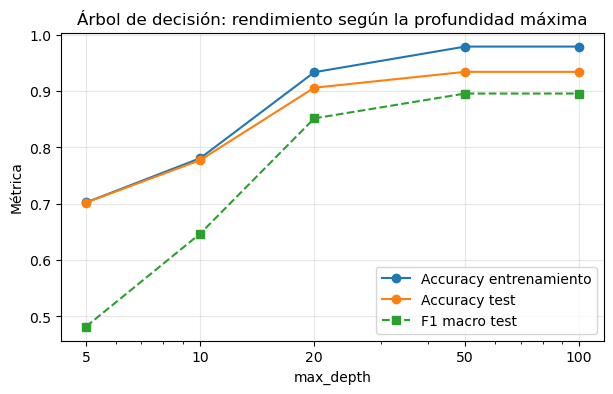

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(max_depth_values, resumen_dt['accuracy_train'], marker='o', label='Accuracy entrenamiento')
ax.plot(max_depth_values, resumen_dt['accuracy_test'], marker='o', label='Accuracy test')
ax.plot(max_depth_values, resumen_dt['f1_macro_test'], marker='s', linestyle='--', label='F1 macro test')
ax.set_xscale('log')
ax.set_xticks(max_depth_values)
ax.set_xticklabels(max_depth_values)
ax.set_xlabel('max_depth')
ax.set_ylabel('Métrica')
ax.set_title('Árbol de decisión: rendimiento según la profundidad máxima')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Visualiza la matriz de confusión del modelo entrenado con 20 niveles.

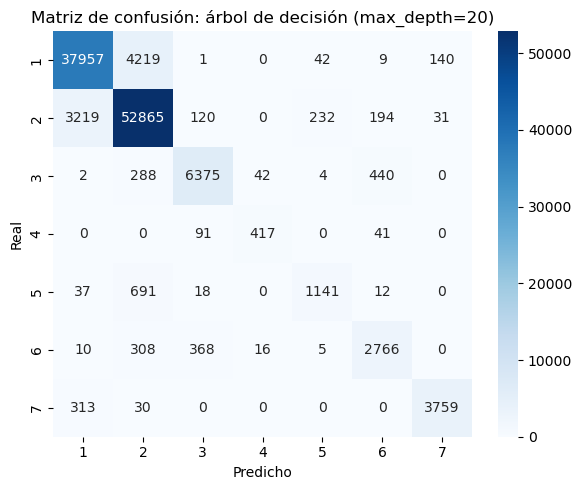

Ejemplos bien clasificados: 105280 de 116203 (90.60%)
Ejemplos mal clasificados:  10923 de 116203


In [20]:
modelo_20 = decisionTrees[max_depth_values.index(20)]
pred_20 = modelo_20.predict(X_test)
clases_orden = sorted(y_test.unique())
cm_20 = confusion_matrix(y_test, pred_20, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_20, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de confusión: árbol de decisión (max_depth=20)')
plt.tight_layout()
plt.show()

correctos_20 = np.trace(cm_20)
print(f"Ejemplos bien clasificados: {correctos_20} de {len(y_test)} ({correctos_20/len(y_test):.2%})")
print(f"Ejemplos mal clasificados:  {len(y_test) - correctos_20} de {len(y_test)}")

In [21]:
print(classification_report(y_test, pred_20, digits=3))


              precision    recall  f1-score   support

           1      0.914     0.896     0.905     42368
           2      0.905     0.933     0.919     56661
           3      0.914     0.891     0.903      7151
           4      0.878     0.760     0.814       549
           5      0.801     0.601     0.687      1899
           6      0.799     0.796     0.798      3473
           7      0.956     0.916     0.936      4102

    accuracy                          0.906    116203
   macro avg      0.881     0.828     0.852    116203
weighted avg      0.906     0.906     0.905    116203



¿Cuántos ejemplos ha clasificado correctamente?

Con `max_depth=20`, el modelo clasifica correctamente **105.280 de 116.203** ejemplos de test (accuracy del 90,60 %) y falla en 10.923.

Mirando la matriz de confusión y el `classification_report` del modelo con `max_depth=20`, sí hay clases que se clasifican mucho mejor que otras:

- **Clases 1 (Spruce/Fir) y 2 (Lodgepole Pine)** concentran el grueso de los errores: 4.219 ejemplos de la clase 1 se predicen como 2 y 3.219 de la clase 2 como 1. Son las dos clases mayoritarias y comparten áreas silvestres y rangos de elevación.
- **Clase 7 (Krummholz)** se clasifica muy bien (precision 0,956; recall 0,916). Es la especie de mayor elevación media (3.362 m) y casi todos sus errores (313) van hacia la clase 1, la otra especie de alta montaña.
- **Clase 5 (Aspen)** es la peor clasificada (recall 0,601). Tiene solo 1.899 ejemplos de test y el modelo la confunde sobre todo con la clase 2 (691 casos).
- **Clase 4 (Cottonwood/Willow)** tiene un recall de 0,760, pero sus errores no van a las clases mayoritarias: van a la 3 (91) y a la 6 (41), las otras especies de Cache la Poudre.
- **Clases 3 (Ponderosa Pine) y 6 (Douglas-fir)** también se confunden entre sí (440 y 368 casos). Ambas dominan Cache la Poudre y tienen medias de elevación casi idénticas (2.395 y 2.419 m).

El patrón es claro: cuanto menos representada está una clase y más comparte hábitat con otra, peor la clasifica el árbol. Con más profundidad mejora de forma notable (ver más adelante), porque el árbol dispone de más niveles para afinar esas fronteras.

¿Cuál de todos los modelos que has entrenado obtiene mejores resultados de precisión para el conjunto de datos de test?

_Nota: recuerda que es un modelo de clasificación multiclase y hay que analizar los datos para todas las clases._

In [22]:
# Mejor modelo en test; en caso de empate se elige la profundidad menor (el modelo más sencillo).
mejor_acc = resumen_dt['accuracy_test'].max()
mejor_depth = min(d for d in max_depth_values if resumen_dt.loc[d, 'accuracy_test'] == mejor_acc)
print(resumen_dt[['accuracy_train', 'accuracy_test', 'f1_macro_test', 'profundidad_real']].round(4))
print(f"\nMejor accuracy de test: max_depth={mejor_depth} con {mejor_acc:.4f}")

           accuracy_train  accuracy_test  f1_macro_test  profundidad_real
max_depth                                                                
5                  0.7023         0.7021         0.4820                 5
10                 0.7809         0.7775         0.6470                10
20                 0.9335         0.9060         0.8516                20
50                 0.9790         0.9342         0.8957                41
100                0.9790         0.9342         0.8957                41

Mejor accuracy de test: max_depth=50 con 0.9342


Selecciona el modelo que consideras que obtiene mejores resultados para los resultados de test. Explica por qué consideras que ese modelo es el que mejor resultados obtiene.

Selecciono el modelo con **`max_depth=50`**. Obtiene la mejor accuracy de test (93,42 %) y también el mejor F1 macro (0,896). `max_depth=100` produce exactamente el mismo árbol, porque el crecimiento se detiene en 41 niveles por efecto de `min_samples_split=10` y `min_samples_leaf=2`, antes de alcanzar cualquiera de los dos límites. Ante ese empate elijo el valor menor.

Frente a `max_depth=20` (90,60 %), la ganancia se concentra en las clases minoritarias: el recall de la clase 5 pasa de 0,601 a 0,793 y el de la clase 4, de 0,760 a 0,811. Hay sobreajuste visible: 97,90 % de accuracy en entrenamiento frente a 93,42 % en test, una diferencia de 4,5 puntos (2,8 con `max_depth=20`). Aun así, el rendimiento en test sigue mejorando al profundizar, así que la complejidad adicional compensa.

Una advertencia metodológica: elegir el modelo con el propio conjunto de test hace que su accuracy sea una estimación algo optimista. Con 116.203 ejemplos de test y solo cinco candidatos el sesgo es pequeño. En la sección de SVM uso validación cruzada para evitarlo.

In [23]:
modelo_ganador_dt = decisionTrees[max_depth_values.index(mejor_depth)]
pred_ganador_dt = modelo_ganador_dt.predict(X_test)
print(f"Modelo seleccionado: max_depth={mejor_depth} (accuracy test = {accuracies_dt[mejor_depth]:.4f})")

Modelo seleccionado: max_depth=50 (accuracy test = 0.9342)


Visualiza la matriz de confusión de los datos de test de este modelo.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?


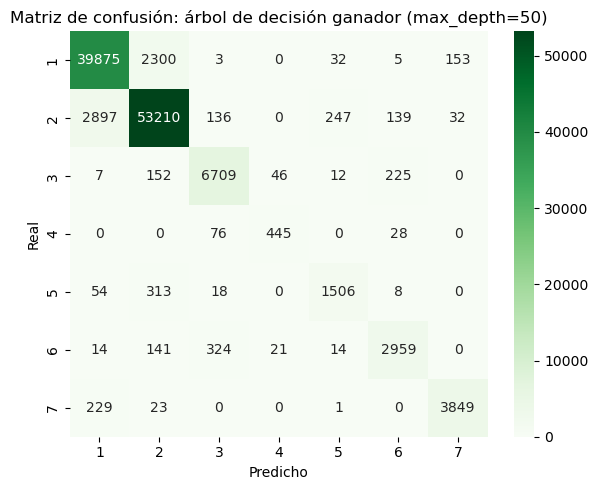

Bien clasificados: 108553 de 116203 (93.42%)
Mal clasificados:  7650 de 116203 (6.58%)


In [24]:
cm_ganador_dt = confusion_matrix(y_test, pred_ganador_dt, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_ganador_dt, annot=True, fmt='d', cmap='Greens', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusión: árbol de decisión ganador (max_depth={mejor_depth})')
plt.tight_layout()
plt.show()

correctos_ganador = np.trace(cm_ganador_dt)
incorrectos_ganador = len(y_test) - correctos_ganador
print(f"Bien clasificados: {correctos_ganador} de {len(y_test)} ({correctos_ganador/len(y_test):.2%})")
print(f"Mal clasificados:  {incorrectos_ganador} de {len(y_test)} ({incorrectos_ganador/len(y_test):.2%})")

Visualiza los valores de precision, recall, f1 para cada una de las clases en este modelo ganador.
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

In [25]:
print(classification_report(y_test, pred_ganador_dt, digits=3))

# Se guardan las métricas del árbol sobre el dataset completo para la comparativa final
metricas_dt_completo = {
    'n_train': len(y_train), 'n_test': len(y_test),
    'accuracy': accuracy_score(y_test, pred_ganador_dt),
    'f1_macro': f1_score(y_test, pred_ganador_dt, average='macro'),
    'f1_por_clase': f1_score(y_test, pred_ganador_dt, average=None, labels=clases_orden),
    'tiempo_fit_s': resumen_dt.loc[mejor_depth, 'tiempo_fit_s'],
}

              precision    recall  f1-score   support

           1      0.926     0.941     0.933     42368
           2      0.948     0.939     0.943     56661
           3      0.923     0.938     0.931      7151
           4      0.869     0.811     0.839       549
           5      0.831     0.793     0.812      1899
           6      0.880     0.852     0.866      3473
           7      0.954     0.938     0.946      4102

    accuracy                          0.934    116203
   macro avg      0.904     0.887     0.896    116203
weighted avg      0.934     0.934     0.934    116203



No, el modelo **no clasifica igual todas las clases**. Las clases 1, 2, 3 y 7 alcanzan un F1 de entre 0,931 y 0,946. Las peores son la 5 (Aspen, F1 = 0,812) y la 4 (Cottonwood/Willow, F1 = 0,839), las dos minoritarias del dataset: 1.899 y 549 ejemplos de test, frente a más de 42.000 de las clases 1 y 2. Douglas-fir (clase 6) queda en medio (F1 = 0,866), y su error principal es confundirse con Ponderosa Pine (324 casos), especie con la que comparte Cache la Poudre.

El F1 *macro* (0,896) es claramente inferior al *weighted* (0,934). Esa diferencia confirma que el desbalanceo penaliza el rendimiento cuando todas las clases cuentan por igual. El modelo tiene más capacidad predictiva para las especies abundantes o muy características por elevación (Krummholz) que para las escasas.

**Support Vector Machine**

In [26]:
# Importamos las librerías para utilizar las máquinas de vector de soportes.
# Utilizaremos la librería svm:

from sklearn import svm

# Cargamos también las librerías para hacer la matriz de confusión y la validación cruzada:

from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.pipeline import make_pipeline

Para la implementación del modelo de clasificación de SVM usaremos la clase Support Vector Classifier de sklearn, https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

El algoritmo de SVM necesita ajustar una serie de hiperparámetros para realizar las clasificaciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de clasificación, nos tenemos que preocupar de los siguientes hiperparámetros:
- C
- kernel
- degree
- gamma

**Indica qué son cada uno de estos hiperparámetros**

- **`C`**: parámetro de regularización. Controla el equilibrio entre maximizar el margen y minimizar los errores de clasificación en entrenamiento. Un `C` bajo tolera más errores a cambio de un margen más amplio (más regularización); un `C` alto penaliza con fuerza cada error y ajusta la frontera a los datos de entrenamiento, con más riesgo de sobreajuste.
- **`kernel`**: función que calcula la similitud entre pares de ejemplos como si fuera un producto escalar en un espacio de mayor dimensión, sin construir ese espacio de forma explícita (*kernel trick*). Así, el SVM puede trazar fronteras no lineales en el espacio original. Las opciones habituales son `"linear"`, `"poly"` (polinómico), `"rbf"` (radial, el más usado para fronteras no lineales) y `"sigmoid"`.
- **`degree`**: grado del polinomio cuando `kernel="poly"`; los demás kernels lo ignoran. Controla la flexibilidad de la frontera polinómica.
- **`gamma`**: coeficiente de los kernels `"rbf"`, `"poly"` y `"sigmoid"`. En el kernel RBF, K(x, x') = exp(−γ‖x − x'‖²), así que γ fija el alcance de la influencia de cada ejemplo. Valores altos generan fronteras muy ajustadas a los puntos cercanos (riesgo de sobreajuste); valores bajos generan fronteras más suaves. Con `gamma="scale"`, el valor por defecto y el que usamos aquí, γ = 1 / (n_features · X.var()), donde `X.var()` es la varianza de toda la matriz de entrenamiento.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro decision_function_shape

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

`decision_function_shape` determina la forma de la función de decisión que devuelve el clasificador cuando hay más de dos clases.

SVM es un clasificador binario en su formulación original, así que para las 7 clases de este problema hay que combinar varios clasificadores binarios. En `SVC` de scikit-learn el entrenamiento es **siempre uno contra uno** (*one-vs-one*): se ajusta un SVM por cada par de clases, 7·6/2 = 21 en nuestro caso, y la predicción se decide por votación. El parámetro no cambia esa estrategia; solo cambia la salida de `decision_function`:

- `"ovo"`: devuelve las 21 puntuaciones originales de libsvm, con forma `(n_samples, 21)`.
- `"ovr"` (valor por defecto): transforma esas puntuaciones en una matriz `(n_samples, 7)`, una columna por clase, como la que devuelven los demás clasificadores de scikit-learn. No se entrenan clasificadores uno contra el resto: la matriz se construye a partir de las puntuaciones uno contra uno.

Su utilidad es práctica. El formato `"ovr"` facilita comparar o combinar el SVM con otros modelos y ordenar las clases por confianza. También permite activar `break_ties=True`, que resuelve los empates de votación usando esa confianza. Si se quisiera un esquema uno contra el resto de verdad, habría que envolver el modelo en `OneVsRestClassifier` o usar `LinearSVC`.

Tenemos un dataset de más de medio millón de instancias, y para el objetivo de la actividad no hacen falta tantas. Además, el dataset presenta desbalanceo entre clases, por lo que es necesario aplicar técnicas de balanceo. Por ello, antes de aplicar SVM vamos a reducir y equilibrar el número de instancias mediante muestreo. SVM requiere una gran carga computacional y con ese volumen de instancias el tiempo requerido sería demasiado elevado

In [27]:
# Reducir el tamaño del dataset (de más de medio millón a n_instancias).
# Según covtype.info, los primeros 11.340 registros forman el subconjunto de entrenamiento del estudio
# original de Blackard y Dean, construido con 1.620 ejemplos de cada clase. Tomar exactamente esas filas
# produce una muestra perfectamente balanceada sin necesidad de remuestrear.
n_instancias = 11340
df = df.head(n_instancias)

**Nota: recuerda revisar que esta manera de seleccionar un subconjunto de instancias nos deja un porcentaje similar de instancias de cada clase, esto es, nuestro dataset debe quedar balanceado. Si no fuera así, deberás cambiar la manera de seleccionar el subconjunto.**

Cover_Type
1    1620
2    1620
3    1620
4    1620
5    1620
6    1620
7    1620


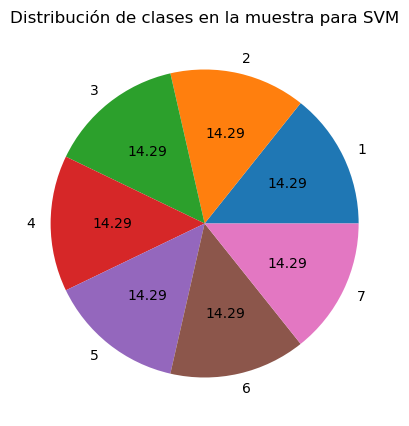

In [28]:
# Comprobamos si efectivamente tenemos un número similar de instancias para cada clase
print(df['Cover_Type'].value_counts().sort_index().to_string())
df['Cover_Type'].value_counts().sort_index().plot(kind='pie', autopct='%.2f')
plt.ylabel('')
plt.title('Distribución de clases en la muestra para SVM')
plt.show()

La muestra queda **perfectamente balanceada**: 1.620 ejemplos de cada clase (14,29 %), muy lejos del desbalanceo original (del 0,47 % al 48,76 %).

No es casualidad. `covtype.info` documenta que en el estudio original de Blackard y Dean los primeros 11.340 registros se usaron como subconjunto de entrenamiento, los 3.780 siguientes como validación y los 565.892 restantes como test. La celda anterior muestra que ese primer bloque contiene exactamente 1.620 ejemplos por clase. Por eso fijé `n_instancias = 11340` en lugar de 10.000: con 10.000 filas el bloque se corta a medias y el reparto deja de ser exacto (entre un 12,6 % y un 16,2 % por clase). Con la muestra balanceada, las diferencias de rendimiento entre clases ya no pueden atribuirse al desbalanceo.

In [29]:
# Con el nuevo número de instancias, separamos los datos en los conjuntos de entrenamiento y test.
from sklearn.model_selection import train_test_split

X, y = df.drop('Cover_Type', axis=1), df['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
print(f"Entrenamiento: {len(X_train)} ejemplos · Test: {len(X_test)} ejemplos")

Entrenamiento: 9072 ejemplos · Test: 2268 ejemplos


Como primer paso para crear un clasificador de SVM hay que decidir si hay que hacer algún preprocesamiento adicional sobre los datos. ¿Hace falta normalizar los datos? Justifica tu respuesta.

**Sí, aquí es imprescindible normalizar**, a diferencia de los árboles de decisión. Un SVM con kernel RBF basa la frontera de decisión en la distancia euclídea entre puntos, porque el kernel calcula `exp(-gamma * ||x_i - x_j||^2)`. Con las variables en su escala original, `Elevation` (rango de miles de metros) o las distancias horizontales (hasta unos 7.000 m) dominarían por completo esa distancia frente a las columnas binarias (rango 0-1) y a los índices de sombreado (0-255), aporten o no información útil. Por eso aplicamos `StandardScaler`, ajustado únicamente con `X_train` para no filtrar información del conjunto de test, y después lo aplicamos a `X_test`.

Una decisión discutible es que también se escalan las 44 columnas binarias. Estandarizar una columna binaria poco frecuente la convierte en un valor grande cuando está activa: un suelo presente en el 1 % de las filas pasa a valer unos 9,9. Eso aumenta su peso en la distancia. La alternativa sería escalar solo las 10 variables continuas con un `ColumnTransformer`; la dejo señalada como posible mejora.

In [30]:
from sklearn.preprocessing import StandardScaler
from pandas import DataFrame

# Se conservan las versiones sin escalar para la validación cruzada (con el escalado dentro de cada
# fold) y para la comparación final con el árbol de decisión.
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()

scaler = StandardScaler()
X_train = DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Datos normalizados con StandardScaler (media 0, desviación estándar 1), ajustado solo con X_train.")
X_train.describe().T[['mean', 'std']].head()

Datos normalizados con StandardScaler (media 0, desviación estándar 1), ajustado solo con X_train.


,mean,std
Elevation,4.730686e-16,1.000055
Aspect,-1.268826e-16,1.000055
Slope,-2.662969e-17,1.000055
Horizontal_Distance_To_Hydrology,6.422454e-17,1.000055
Vertical_Distance_To_Hydrology,-3.759485e-17,1.000055


Entrena un conjunto de modelos de SVM que utilicen todas las variables del dataset, con C = 0.1 hasta 1000 con cinco valores diferentes. Utiliza kernel radial, y gamma con valor *scale*.

In [31]:
from sklearn.svm import SVC

C = [0.1, 1, 10, 100, 1000]
kernel = 'rbf'
gamma = 'scale'

svc = [SVC(C=i, kernel=kernel, gamma=gamma) for i in C]
svc


[SVC(C=0.1), SVC(C=1), SVC(C=10), SVC(C=100), SVC(C=1000)]

In [32]:
from sklearn.metrics import accuracy_score, f1_score
import time

score = []
modelos_svm = []
resultados_svm = []
for modelo in svc:
    t0 = time.time()
    modelo.fit(X_train, y_train)
    t_fit = time.time() - t0
    pred = modelo.predict(X_test)
    acc = accuracy_score(y_test, pred)
    score.append(acc)
    modelos_svm.append(modelo)
    resultados_svm.append({
        'C': modelo.C,
        'accuracy_train': accuracy_score(y_train, modelo.predict(X_train)),
        'accuracy_test': acc,
        'f1_macro_test': f1_score(y_test, pred, average='macro'),
        'vectores_soporte': modelo.n_support_.sum(),
        'tiempo_fit_s': round(t_fit, 1),
    })

resumen_svm = pd.DataFrame(resultados_svm).set_index('C')
resumen_svm.round(4)

,accuracy_train,accuracy_test,f1_macro_test,vectores_soporte,tiempo_fit_s
C,,,,,
0.1,0.6403,0.6151,0.6130,7006,7.1
1.0,0.7363,0.7063,0.7023,6028,4.9
10.0,0.8265,0.7822,0.7775,5206,4.0
100.0,0.8868,0.8051,0.8011,4528,4.6
1000.0,0.9410,0.8086,0.8068,4077,8.1


In [33]:
score

[0.6150793650793651,
 0.7063492063492064,
 0.7821869488536155,
 0.8051146384479718,
 0.808641975308642]

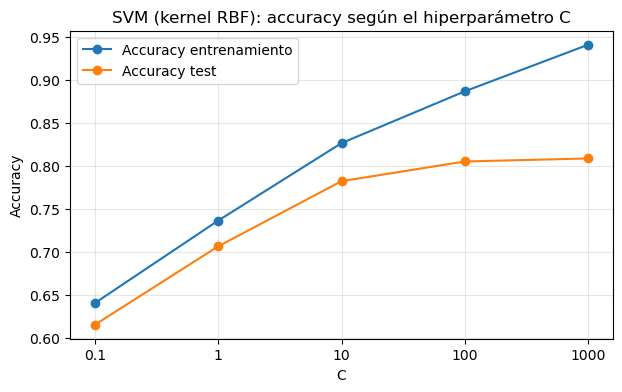

In [34]:
fig, ax = plt.subplots(figsize=(7, 4))
etiquetas_c = [str(c) for c in C]
ax.plot(etiquetas_c, resumen_svm['accuracy_train'], marker='o', label='Accuracy entrenamiento')
ax.plot(etiquetas_c, resumen_svm['accuracy_test'], marker='o', label='Accuracy test')
ax.set_xlabel('C')
ax.set_ylabel('Accuracy')
ax.set_title('SVM (kernel RBF): accuracy según el hiperparámetro C')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [35]:
# Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento.
# El escalado va dentro del pipeline para que cada fold se normalice solo con sus propios datos.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
resultados_cv = []
for c_val in C:
    pipe = make_pipeline(StandardScaler(), SVC(C=c_val, kernel=kernel, gamma=gamma))
    s = cross_val_score(pipe, X_train_raw, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    resultados_cv.append({'C': c_val, 'cv_accuracy_media': s.mean(), 'cv_desviacion': s.std()})

resumen_cv = pd.DataFrame(resultados_cv).set_index('C')
resumen_cv.round(4)

,cv_accuracy_media,cv_desviacion
C,,
0.1,0.6232,0.0075
1.0,0.7140,0.0071
10.0,0.7804,0.0117
100.0,0.8080,0.0062
1000.0,0.8116,0.0044


Después de hacer el entrenamiento, visualiza las matrices de confusión de los modelos entrenados.

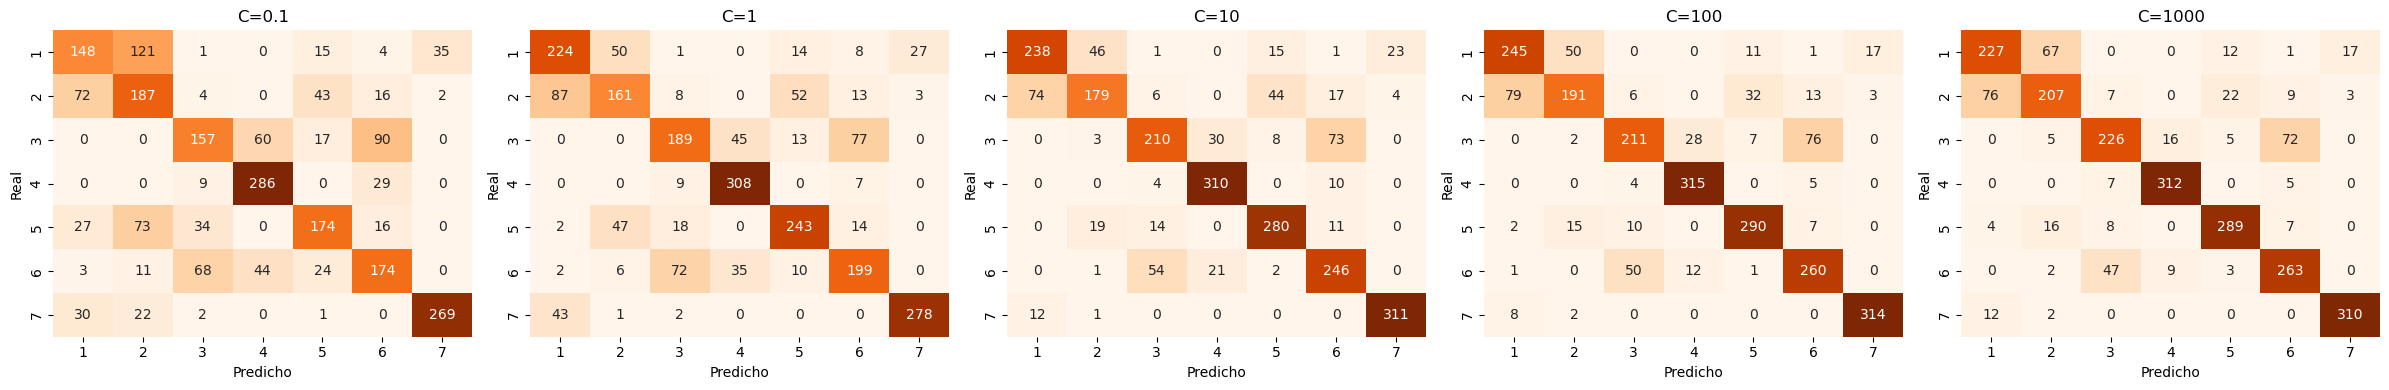

In [36]:
fig, axes = plt.subplots(1, len(C), figsize=(24, 4))
for ax, c_val, modelo in zip(axes, C, modelos_svm):
    pred = modelo.predict(X_test)
    clases_orden = sorted(y_test.unique())
    cm = confusion_matrix(y_test, pred, labels=clases_orden)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax, cbar=False, xticklabels=clases_orden, yticklabels=clases_orden)
    ax.set_title(f"C={c_val}")
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
plt.tight_layout()
plt.show()


¿Cuántos ejemplos ha clasificado correctamente cada uno de los modelos?

In [37]:
correctos_por_c = pd.DataFrame({
    'bien clasificados': [int((m.predict(X_test) == y_test).sum()) for m in modelos_svm],
    'mal clasificados': [int((m.predict(X_test) != y_test).sum()) for m in modelos_svm],
    'accuracy_test': score,
}, index=pd.Index(C, name='C'))
print(f"Ejemplos de test: {len(y_test)}")
correctos_por_c

Ejemplos de test: 2268


,bien clasificados,mal clasificados,accuracy_test
C,,,
0.1,1395,873,0.615079
1.0,1602,666,0.706349
10.0,1774,494,0.782187
100.0,1826,442,0.805115
1000.0,1834,434,0.808642


Ejemplos bien clasificados de los 2.268 de test, por valor de `C`:

| C | Bien clasificados | Mal clasificados | Accuracy |
| --- | --- | --- | --- |
| 0,1 | 1.395 | 873 | 61,51 % |
| 1 | 1.602 | 666 | 70,63 % |
| 10 | 1.774 | 494 | 78,22 % |
| 100 | 1.826 | 442 | 80,51 % |
| 1000 | 1.834 | 434 | 80,86 % |

La accuracy sube de forma sostenida de `C=0,1` a `C=100` y casi se estabiliza entre `C=100` y `C=1000`, con solo 8 ejemplos de diferencia. En entrenamiento, en cambio, sigue creciendo (del 88,68 % al 94,10 %). A partir de `C=100`, subir `C` hace que el modelo se ajuste más al entrenamiento sin generalizar mejor.

Selecciona el modelo que consideras que obtiene mejores resultados y realiza las predicciones con el conjunto de datos de test.

In [38]:
# El modelo se elige con la validación cruzada, no con el conjunto de test: así el test queda como
# estimación independiente del rendimiento. En caso de empate se elige el C menor (más regularización).
mejor_cv = resumen_cv['cv_accuracy_media'].max()
mejor_C = min(c for c in C if resumen_cv.loc[c, 'cv_accuracy_media'] == mejor_cv)
modelo_ganador_svm = modelos_svm[C.index(mejor_C)]
pred_ganador_svm = modelo_ganador_svm.predict(X_test)
print(f"Modelo seleccionado: C={mejor_C} "
      f"(accuracy CV = {mejor_cv:.4f} ± {resumen_cv.loc[mejor_C, 'cv_desviacion']:.4f}; "
      f"accuracy test = {accuracy_score(y_test, pred_ganador_svm):.4f})")

Modelo seleccionado: C=1000 (accuracy CV = 0.8116 ± 0.0044; accuracy test = 0.8086)


Selecciono **`C=1000`**. Obtiene la mejor accuracy media en validación cruzada (81,16 % ± 0,44) y también la mejor en test (80,86 %: 1.834 de 2.268). Elegirlo con la validación cruzada, y no con el test, mantiene el conjunto de test como estimación independiente del rendimiento.

Hay dos matices. El primero es que la diferencia con `C=100` (80,80 % ± 0,62 en validación cruzada) es menor que una desviación estándar, así que ambos modelos son prácticamente equivalentes. El segundo es que `C=1000` sobreajusta más: 94,10 % en entrenamiento frente a 80,86 % en test, 13,2 puntos de diferencia, frente a 8,2 con `C=100`. Una regla de parsimonia que eligiera el modelo más simple dentro de una desviación estándar del mejor habría escogido `C=100`. Mantengo `C=1000` por el criterio que fijé de antemano, con esa salvedad.

El menor número de vectores de soporte de `C=1000` (4.077 frente a 4.528) no indica menos sobreajuste. Al subir `C` se penalizan más los errores de entrenamiento, el margen se estrecha y quedan menos puntos dentro de él.

Visualiza la matriz de confusión de los datos de test para este modelo ganador.
- ¿Cuántos ejemplos ha clasificado bien el modelo?
- ¿Cuántos ejemplos ha clasificado de manera errónea?

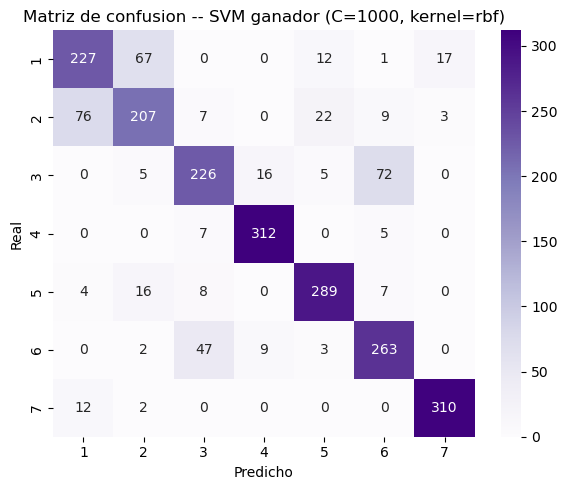

Bien clasificados: 1834 de 2268 (80.86%)
Mal clasificados: 434 de 2268 (19.14%)


In [39]:
clases_orden = sorted(y_test.unique())
cm_ganador_svm = confusion_matrix(y_test, pred_ganador_svm, labels=clases_orden)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_ganador_svm, annot=True, fmt='d', cmap='Purples', ax=ax, xticklabels=clases_orden, yticklabels=clases_orden)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusion -- SVM ganador (C={mejor_C}, kernel=rbf)')
plt.tight_layout()
plt.show()

correctos_svm = np.trace(cm_ganador_svm)
incorrectos_svm = len(y_test) - correctos_svm
print(f"Bien clasificados: {correctos_svm} de {len(y_test)} ({correctos_svm/len(y_test):.2%})")
print(f"Mal clasificados: {incorrectos_svm} de {len(y_test)} ({incorrectos_svm/len(y_test):.2%})")


Visualiza los valores de precision, recall, f1 para cada una de las clases en este modelo ganador.
- ¿Clasifica de igual manera todas las clases o hay alguna para la que el modelo tiene una mayor capacidad predictiva?

In [40]:
print(classification_report(y_test, pred_ganador_svm, digits=3))


              precision    recall  f1-score   support

           1      0.712     0.701     0.706       324
           2      0.692     0.639     0.665       324
           3      0.766     0.698     0.730       324
           4      0.926     0.963     0.944       324
           5      0.873     0.892     0.882       324
           6      0.737     0.812     0.772       324
           7      0.939     0.957     0.948       324

    accuracy                          0.809      2268
   macro avg      0.806     0.809     0.807      2268
weighted avg      0.806     0.809     0.807      2268



No, tampoco aquí el modelo **clasifica igual todas las clases**. Las mejor separadas son la 7 (Krummholz, F1 = 0,948) y la 4 (Cottonwood/Willow, 0,944), seguidas de la 5 (Aspen, 0,882). Las más difíciles son la 2 (Lodgepole Pine, 0,665) y la 1 (Spruce/Fir, 0,706), y después la 3 (Ponderosa Pine, 0,730) y la 6 (Douglas-fir, 0,772).

La matriz de confusión muestra dos bloques de error:

- **1 ↔ 2**: 67 ejemplos de la clase 1 predichos como 2 y 76 de la clase 2 predichos como 1.
- **3 ↔ 6**: 72 ejemplos de la clase 3 predichos como 6 y 47 de la clase 6 predichos como 3.

Como la muestra está balanceada, el desbalanceo ya no explica estas diferencias. La dificultad viene de que cada par comparte hábitat. Spruce/Fir y Lodgepole Pine conviven en Rawah y Comanche Peak, con elevaciones medias de 3.129 y 2.921 m y rangos muy solapados. Ponderosa Pine y Douglas-fir son las especies principales de Cache la Poudre, con medias de 2.395 y 2.419 m. En cambio, Krummholz (la especie más alta) y Cottonwood/Willow (la más baja, casi exclusiva de Cache la Poudre) ocupan extremos de elevación que el kernel RBF separa con facilidad.

**Comparativa**

En base al EDA realizado, a las decisiones tomadas sobre los datos e hiperparámetros y a las características computacionales de tu equipo. ¿Qué modelo obtiene mejores resultados de clasificación?

In [41]:
# Comparación en igualdad de condiciones: árbol de decisión entrenado con los MISMOS ejemplos balanceados
# que el SVM y evaluado sobre el MISMO conjunto de test (sin escalar: al árbol no le afecta).
# La profundidad se elige con la misma validación cruzada estratificada que se usó para C.
resultados_dt_eq = []
for depth in max_depth_values:
    arbol = DecisionTreeClassifier(criterion='gini', max_depth=depth, min_samples_split=10,
                                   min_samples_leaf=2, max_features=None, random_state=1)
    s = cross_val_score(arbol, X_train_raw, y_train, cv=cv, scoring='accuracy')
    resultados_dt_eq.append({'max_depth': depth, 'cv_accuracy_media': s.mean(), 'cv_desviacion': s.std()})
resumen_dt_eq = pd.DataFrame(resultados_dt_eq).set_index('max_depth')
print(resumen_dt_eq.round(4))

mejor_cv_dt = resumen_dt_eq['cv_accuracy_media'].max()
depth_eq = min(d for d in max_depth_values if resumen_dt_eq.loc[d, 'cv_accuracy_media'] == mejor_cv_dt)
arbol_eq = DecisionTreeClassifier(criterion='gini', max_depth=depth_eq, min_samples_split=10,
                                  min_samples_leaf=2, max_features=None, random_state=1)
t0 = time.time(); arbol_eq.fit(X_train_raw, y_train); t_arbol_eq = time.time() - t0
pred_arbol_eq = arbol_eq.predict(X_test_raw)
print(f"\nÁrbol elegido por CV: max_depth={depth_eq} (profundidad real {arbol_eq.get_depth()})")
print(classification_report(y_test, pred_arbol_eq, digits=3))

           cv_accuracy_media  cv_desviacion
max_depth                                  
5                     0.6599         0.0100
10                    0.7335         0.0041
20                    0.7404         0.0098
50                    0.7385         0.0075
100                   0.7385         0.0075

Árbol elegido por CV: max_depth=20 (profundidad real 20)
              precision    recall  f1-score   support

           1      0.620     0.639     0.629       324
           2      0.631     0.586     0.608       324
           3      0.713     0.759     0.735       324
           4      0.925     0.907     0.916       324
           5      0.821     0.877     0.848       324
           6      0.757     0.710     0.732       324
           7      0.878     0.867     0.873       324

    accuracy                          0.764      2268
   macro avg      0.763     0.764     0.763      2268
weighted avg      0.763     0.764     0.763      2268



                                          ejemplos train                  test  accuracy  F1 macro  tiempo fit (s)
modelo                                                                                                            
Árbol, dataset completo (max_depth=50)            464809  116203 desbalanceado    0.9342    0.8957           22.40
Árbol, muestra balanceada (max_depth=20)            9072       2268 balanceado    0.7637    0.7631            0.34
SVM RBF, muestra balanceada (C=1000)                9072       2268 balanceado    0.8086    0.8068            9.32


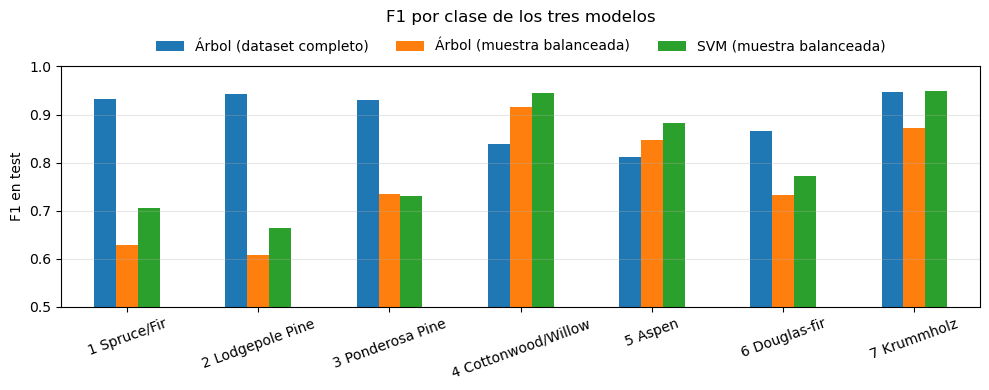

In [42]:
t0 = time.time(); SVC(C=mejor_C, kernel=kernel, gamma=gamma).fit(X_train, y_train); t_svm = time.time() - t0

comparativa = pd.DataFrame([
    {'modelo': f'Árbol, dataset completo (max_depth={mejor_depth})', 'ejemplos train': metricas_dt_completo['n_train'],
     'test': f"{metricas_dt_completo['n_test']} desbalanceado", 'accuracy': metricas_dt_completo['accuracy'],
     'F1 macro': metricas_dt_completo['f1_macro'], 'tiempo fit (s)': metricas_dt_completo['tiempo_fit_s']},
    {'modelo': f'Árbol, muestra balanceada (max_depth={depth_eq})', 'ejemplos train': len(y_train),
     'test': f'{len(y_test)} balanceado', 'accuracy': accuracy_score(y_test, pred_arbol_eq),
     'F1 macro': f1_score(y_test, pred_arbol_eq, average='macro'), 'tiempo fit (s)': round(t_arbol_eq, 2)},
    {'modelo': f'SVM RBF, muestra balanceada (C={mejor_C})', 'ejemplos train': len(y_train),
     'test': f'{len(y_test)} balanceado', 'accuracy': accuracy_score(y_test, pred_ganador_svm),
     'F1 macro': f1_score(y_test, pred_ganador_svm, average='macro'), 'tiempo fit (s)': round(t_svm, 2)},
]).set_index('modelo')
print(comparativa.round(4).to_string())

f1_clases = pd.DataFrame({
    'Árbol (dataset completo)': metricas_dt_completo['f1_por_clase'],
    'Árbol (muestra balanceada)': f1_score(y_test, pred_arbol_eq, average=None, labels=clases_orden),
    'SVM (muestra balanceada)': f1_score(y_test, pred_ganador_svm, average=None, labels=clases_orden),
}, index=[f'{c} {NOMBRES_CLASE[c]}' for c in clases_orden])

fig, ax = plt.subplots(figsize=(10, 4))
f1_clases.plot(kind='bar', ax=ax, rot=20)
ax.set_ylabel('F1 en test')
ax.set_ylim(0.5, 1.0)
ax.set_title('F1 por clase de los tres modelos', pad=32)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

La respuesta depende de cómo se compare, y cambia al igualar las condiciones.

**En accuracy bruta gana el árbol del dataset completo**: 93,42 % frente al 80,86 % del SVM. Pero esa comparación mezcla tres diferencias. El árbol aprende de 464.809 ejemplos y el SVM de 9.072, 51 veces menos. El árbol se evalúa sobre el test desbalanceado original, donde el 85 % de los casos son de las clases 1 y 2, y el SVM sobre un test balanceado. Y la accuracy premia acertar en las clases mayoritarias. Incluso el F1 macro (0,896 frente a 0,807) arrastra la diferencia en cantidad de datos.

Para aislar el efecto del algoritmo entrené un árbol con los mismos 9.072 ejemplos balanceados, eligiendo la profundidad con la misma validación cruzada (`max_depth=20`), y lo evalué sobre los mismos 2.268 ejemplos de test. **En igualdad de condiciones gana el SVM**: 80,86 % frente a 76,37 % de accuracy y 0,807 frente a 0,763 de F1 macro. Supera al árbol en seis de las siete clases; solo Ponderosa Pine queda prácticamente empatada (0,730 frente a 0,735). Además, la validación cruzada del árbol se estanca en torno al 74 % a partir de `max_depth=20`. Con pocos datos, el árbol particiona el espacio en rectángulos que sobreajustan, mientras que la frontera suave del kernel RBF aprovecha mejor la estructura continua de la elevación y las distancias.

Las características computacionales cambian la recomendación práctica. El árbol entrena el dataset completo en unos 7 s en este equipo y no necesita escalado. El SVM tarda unos 3 s con solo 9.072 ejemplos, y el coste de `SVC` crece al menos de forma cuadrática con el número de ejemplos, así que entrenarlo con los 464.809 ejemplos no es viable sin aproximaciones de kernel (Nystroem) o un SVM lineal. Mi conclusión:

- **Con los recursos disponibles, el árbol de decisión es la mejor opción**, porque puede aprovechar todo el dataset, y esa cantidad de datos pesa más que la ventaja del algoritmo.
- **A igualdad de datos, el SVM clasifica mejor.**

Dos observaciones más apoyan este análisis. La primera: el árbol entrenado con datos balanceados reconoce mejor Cottonwood/Willow (recall de 0,907 frente a 0,811 del árbol completo), pese a disponer de menos ejemplos de ella (1.296 frente a 2.198). Lo que la perjudicaba en el dataset completo era su proporción mínima frente a las demás clases, no el número absoluto de ejemplos. La segunda: los tres modelos coinciden en el patrón de error, con Spruce/Fir ↔ Lodgepole Pine y Ponderosa Pine ↔ Douglas-fir como pares más difíciles. Son especies que comparten área y rango de elevación, así que la dificultad está en los propios datos más que en un algoritmo concreto.

Como referencia externa, `covtype.info` recoge un 70 % de acierto con una red neuronal y un 58 % con análisis discriminante lineal en el estudio original. Aquellos modelos se entrenaron con los mismos 11.340 registros balanceados, pero se evaluaron sobre los 565.892 restantes, con la distribución natural de clases, así que la cifra no es comparable directamente con nuestro test. Aun así, sitúa a ambos modelos por encima de esas líneas base.

### Investigación

Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de **clasificación** empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.

**Referencia APA:**

Thanh Noi, P., & Kappas, M. (2018). Comparison of Random Forest, k-Nearest Neighbor, and Support Vector Machine classifiers for land cover classification using Sentinel-2 imagery. *Sensors*, *18*(1), 18. https://doi.org/10.3390/s18010018

**Cumplimiento de los requisitos.** Artículo publicado en una revista científica revisada por pares (*Sensors*, MDPI), en línea desde el 22 de diciembre de 2017 y asignado al volumen de 2018, por tanto posterior a 2015. Resuelve un problema de **clasificación** con SVM como uno de los tres clasificadores comparados (junto con Random Forest, un ensamble de árboles de decisión, y k-NN). No utiliza técnicas de *deep learning*.

---

**Objetivo de la investigación**

El problema real es la elaboración de mapas de uso y cobertura del suelo, un insumo básico para la planificación urbana, la gestión de recursos naturales y el seguimiento agrícola. Los autores clasifican una zona de 30 × 30 km en el delta del río Rojo (Vietnam) en seis clases: residencial, superficie impermeable, agricultura, suelo desnudo, bosque y agua. Para ello usan una imagen del satélite Sentinel-2 del 3 de junio de 2017, con 10 bandas espectrales remuestreadas a 20 m. El estudio tiene dos objetivos: comparar el rendimiento de SVM, Random Forest y k-NN sobre esta imagen, y evaluar cómo influyen el tamaño de la muestra de entrenamiento y su balanceo en la exactitud de cada clasificador.

**Cómo se utilizan las técnicas de clasificación**

Cada píxel es un ejemplo cuyas variables son las reflectancias en las 10 bandas. Las muestras de entrenamiento proceden de 135 polígonos por clase, digitalizados por interpretación visual de la propia imagen y de Google Earth. Para el test se recogieron 650 puntos por clase y se descartaron los que quedaban a menos de 15 m de un polígono de entrenamiento, para garantizar la independencia entre ambos conjuntos. Con los datos de entrenamiento construyeron 14 subconjuntos:

- 7 desbalanceados, con el 5 %, 10 %, 20 %, 40 %, 60 %, 80 % y 100 % de los píxeles, conservando la proporción de clases.
- 7 balanceados, con 50, 125, 250, 500, 750, 1.000 y 1.250 píxeles por clase.

El SVM usa **kernel RBF**, igual que en esta actividad, y sus dos hiperparámetros se ajustan por búsqueda en rejilla: diez valores de C (de 2⁻² a 2⁷) y diez de γ (de 2⁻⁵ a 2⁴), es decir, 100 combinaciones para cada uno de los 14 subconjuntos. Para Random Forest se exploraron 100, 200, 500 y 1.000 árboles y de 1 a 10 variables por división (`mtry`); se fijó `ntree = 500` y `mtry` entre 2 y 4. Para k-NN se probó k de 1 a 20 y el mejor resultado se obtuvo con k = 1. **No se adapta ni modifica ningún algoritmo**: la aportación está en el diseño experimental, que cruza tamaño de muestra, balanceo y ajuste sistemático de hiperparámetros sobre el mismo conjunto de test. La métrica principal es la exactitud global (OA), con su intervalo de confianza al 95 %.

**Principales resultados**

- Todas las clasificaciones alcanzaron una OA de entre el 90 % y el 95 %. **SVM fue el mejor clasificador en prácticamente todos los escenarios**: 95,32 % como máximo con datos desbalanceados y 95,29 % con datos balanceados, frente al 94,70 % de Random Forest y el 94,59 % de k-NN.
- SVM fue también **el menos sensible al tamaño de la muestra**. Con los subconjuntos más pequeños (unos 50 píxeles por clase) obtuvo entre un 93,76 % y un 93,96 % con datos desbalanceados, frente a un 89,80–92,06 % de k-NN y un 90,71–92,34 % de Random Forest.
- Los valores óptimos de C fueron altos (entre 32 y 128) y los de γ, bajos. El mismo patrón aparece en esta actividad, donde el rendimiento mejora al subir C hasta 100–1.000.
- Con muestras suficientemente grandes, por encima de unos 750 píxeles por clase, los tres clasificadores convergen a exactitudes similares (más del 93,85 %), y la diferencia entre datos balanceados y desbalanceados deja de ser significativa. Los autores recomiendan que la muestra de entrenamiento represente en torno al 0,25 % del área de estudio.

**Relación con esta actividad.** El artículo refuerza la conclusión de la comparativa: con una cantidad moderada de ejemplos, el SVM con kernel RBF generaliza mejor que los modelos basados en árboles, y la ventaja se diluye cuando hay datos abundantes. Una limitación del trabajo es que compara los clasificadores solo con la exactitud global. En este cuaderno, el F1 por clase y el F1 macro han mostrado diferencias entre clases minoritarias que esa métrica por sí sola no revela.